In [66]:
# We have added LangSmith's API key, endpoint and project's name in .env.chatbot file 
# So just load that particular files using load_dotenv()
# We don't need to make any changes in backend file.

from dotenv import load_dotenv

from langchain_core.messages import HumanMessage

from langchain_openai import ChatOpenAI
from langchain_google_genai import ChatGoogleGenerativeAI

from typing import TypedDict, Annotated
from langgraph.graph import StateGraph, START, END
from langchain_core.messages import BaseMessage
from langgraph.checkpoint.memory import InMemorySaver
import sqlite3
from langgraph.graph.message import add_messages

from langgraph.prebuilt import ToolNode, tools_condition
from langchain_core.tools import tool
from langchain_community.utilities import GoogleSerperAPIWrapper
import requests


In [67]:
load_dotenv(".env.chatbot")    # Serper_API_KEY is added in .env.chatbot file

True

In [68]:
# Creating the model
model_gemini = ChatGoogleGenerativeAI(
    model = 'gemini-2.5-flash')

model_openai = ChatOpenAI(
    model = 'gpt-3.5-turbo'
)

In [69]:
# Creating Tools

# google search tool

@tool
def google_search(query: str)-> any:
    '''
    This function takes a query as input and searches for its answer on Google Search Engine.
    You can pass any query.
    '''
    search = GoogleSerperAPIWraper(type = 'search')
    
    return search.result

# ------------------------------------------------------------------------------------------------------------------------

# Whether tool
@tool
def whether_search(city:str) ->str:
    '''
    This function returns the live whether data of any city in the world.
    Pass any city name and it will return all the whether details.
    '''

    api_key = '6018a20db02a3eb6aa1ef7bffa662350'

    url = f"http://api.weatherstack.com/current?access_key={api_key}&query={city}"

    response = requests.get(url)

    return response.json()

# Train details tool
@tool
def fetch_train_details(train_number: str) -> str:

    '''
    Given train number, this function fetches all the deetails regarding
    train like train schedule, stations, station timings, when train reaches at different stations,
    Time when train departs from in-between stations, Names of In-between stations. 
    '''
    url = "https://irctc-insight.p.rapidapi.com/api/v1/train-details"
    
    headers = {
        "x-rapidapi-key": "a386df66c3msha0ef942c346306dp107a95jsn1c48df211ae1",
        "x-rapidapi-host": "irctc-insight.p.rapidapi.com",
        "Content-Type": "application/json"
    }
    
    payload = {"trainNo": train_number}
    
    response = requests.post(url, json = payload, headers = headers)
    return response.json()

In [70]:
# Binding tools
tools_list = [google_search, whether_search, fetch_train_details]
model_with_tools = model_gemini.bind_tools(tools_list)

In [71]:
# Defining the state
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [72]:
# Defining nodes
def chat_node(state: ChatState) ->ChatState:

    # Fetching messages
    messages = state["messages"]

    # Invokig model
    response = model_with_tools.invoke(messages)

    # Appending AI's response to the messages list
    return {"messages": [response]}

In [73]:
checkpointer = InMemorySaver()

In [74]:
# tool node
tools_node = ToolNode(tools_list)

# Defining graph
graph = StateGraph(ChatState)

# Adding nodes
graph.add_node('chat_node', chat_node)
graph.add_node("tools", tools_node)   # For tools, name should be only 'tools', nothing else

# Creating edges
graph.add_edge(START, 'chat_node')
graph.add_conditional_edges('chat_node', tools_condition)
# graph.add_edge("tools_node", END)
# Compiling the graph
workflow = graph.compile(name = 'Streamlit chatbot', checkpointer = checkpointer)

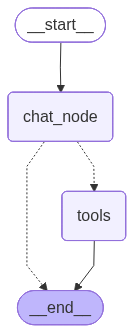

In [75]:
workflow

In [76]:
initial_state = {'messages': [HumanMessage('When train number 22959 reaches Rajkot Junction')]}
config = {"configurable": {'thread_id': '1'}}

response = workflow.invoke(initial_state, config = config)

In [77]:
response

# See, this returns so many key_value pairs and there will be our answere present somewhere.
# But it is not giving us direct answer to our question.

# So we'll have to send the response of tool along with our question to llm and llm will return us proper answer.

{'messages': [HumanMessage(content='When train number 22959 reaches Rajkot Junction', additional_kwargs={}, response_metadata={}, id='642324fb-142a-4ca7-bd34-4cffd7d887a8'),
  AIMessage(content='', additional_kwargs={'function_call': {'name': 'fetch_train_details', 'arguments': '{"train_number": "22959"}'}}, response_metadata={'prompt_feedback': {'block_reason': 0, 'safety_ratings': []}, 'finish_reason': 'STOP', 'safety_ratings': []}, id='lc_run--206a5c4d-ed50-414b-bed7-c7b4e9bc0fd2-0', tool_calls=[{'name': 'fetch_train_details', 'args': {'train_number': '22959'}, 'id': '8ce51d92-59da-4e48-86d1-68dbc569d773', 'type': 'tool_call'}], usage_metadata={'input_tokens': 220, 'output_tokens': 23, 'total_tokens': 350, 'input_token_details': {'cache_read': 0}}),
  ToolMessage(content='{"status": true, "data": {"trainNumber": "22959", "trainName": "INTERCITY EXP", "route": "Vadodara Junction to Jamnagar", "runningDays": {"Mon": true, "Tue": true, "Wed": true, "Thu": true, "Fri": true, "Sat": true

# Making changes in edges of the graph

In [78]:
# tool node
tools_node = ToolNode(tools_list)

# Defining graph
graph = StateGraph(ChatState)

# Adding nodes
graph.add_node('chat_node', chat_node)
graph.add_node("tools", tools_node)   # For tools, name should be only 'tools', nothing else

# Creating edges
graph.add_edge(START, 'chat_node')
graph.add_conditional_edges('chat_node', tools_condition)
graph.add_edge("tools", 'chat_node')

# Compiling the graph
workflow = graph.compile(name = 'Streamlit chatbot', checkpointer = checkpointer)

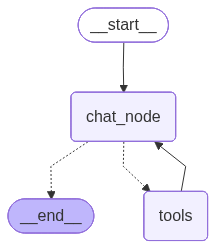

In [79]:
workflow

In [80]:
initial_state = {'messages': [HumanMessage('When train number 22959 reaches Rajkot Junction')]}
config = {"configurable": {'thread_id': '1'}}

response = workflow.invoke(initial_state, config = config)

In [81]:
response["messages"] [-1].content

'Train number 22959 reaches Rajkot Junction at 21:44.'

In [82]:
response

{'messages': [HumanMessage(content='When train number 22959 reaches Rajkot Junction', additional_kwargs={}, response_metadata={}, id='642324fb-142a-4ca7-bd34-4cffd7d887a8'),
  AIMessage(content='', additional_kwargs={'function_call': {'name': 'fetch_train_details', 'arguments': '{"train_number": "22959"}'}}, response_metadata={'prompt_feedback': {'block_reason': 0, 'safety_ratings': []}, 'finish_reason': 'STOP', 'safety_ratings': []}, id='lc_run--206a5c4d-ed50-414b-bed7-c7b4e9bc0fd2-0', tool_calls=[{'name': 'fetch_train_details', 'args': {'train_number': '22959'}, 'id': '8ce51d92-59da-4e48-86d1-68dbc569d773', 'type': 'tool_call'}], usage_metadata={'input_tokens': 220, 'output_tokens': 23, 'total_tokens': 350, 'input_token_details': {'cache_read': 0}}),
  ToolMessage(content='{"status": true, "data": {"trainNumber": "22959", "trainName": "INTERCITY EXP", "route": "Vadodara Junction to Jamnagar", "runningDays": {"Mon": true, "Tue": true, "Wed": true, "Thu": true, "Fri": true, "Sat": true

In [83]:
response['messages'][-1]

AIMessage(content='Train number 22959 reaches Rajkot Junction at 21:44.', additional_kwargs={}, response_metadata={'prompt_feedback': {'block_reason': 0, 'safety_ratings': []}, 'finish_reason': 'STOP', 'safety_ratings': []}, id='lc_run--486f7680-1ec6-4efc-9473-087c209943e0-0', usage_metadata={'input_tokens': 1456, 'output_tokens': 20, 'total_tokens': 1759, 'input_token_details': {'cache_read': 0}})

In [84]:
a = list(checkpointer.list(None))
a

[CheckpointTuple(config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f0defb9-f6f1-653f-8005-6af39a7982d3'}}, checkpoint={'v': 4, 'ts': '2025-12-22T06:01:14.150022+00:00', 'id': '1f0defb9-f6f1-653f-8005-6af39a7982d3', 'channel_versions': {'__start__': '00000000000000000000000000000006.0.4004107184089486', 'messages': '00000000000000000000000000000007.0.6075404364221484', 'branch:to:chat_node': '00000000000000000000000000000007.0.6075404364221484', 'branch:to:tools': '00000000000000000000000000000004.0.06433418127932988'}, 'versions_seen': {'__input__': {}, '__start__': {'__start__': '00000000000000000000000000000005.0.8147967297856522'}, 'chat_node': {'branch:to:chat_node': '00000000000000000000000000000006.0.4004107184089486'}, 'tools': {'branch:to:tools': '00000000000000000000000000000003.0.5297676997431099'}}, 'updated_channels': ['messages'], 'channel_values': {'messages': [HumanMessage(content='When train number 22959 reaches Rajkot Junction', additio

In [85]:
print(a[0].config)
print()

print(a[0].config['configurable'])
print()

print(a[0].config ['configurable'] ['thread_id'])

{'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f0defb9-f6f1-653f-8005-6af39a7982d3'}}

{'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f0defb9-f6f1-653f-8005-6af39a7982d3'}

1
